# Series de tiempo: diferenciar o no diferenciar, y qué tan confiables son los intervalos

**Perfil:** Cuantitativo y ciencia de datos  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

La primera decisión de un modelo ARIMA —**¿diferenciar?**— depende de si la tendencia es determinista o estocástica. ¿Pueden las pruebas de raíz unitaria decidirlo? ¿Qué cuesta equivocarse en el **error** y en la **cobertura de los intervalos** de pronóstico? ¿Y los criterios de información eligen bien?

## Recorrido

1. Dos mundos con verdad conocida: **tendencia determinista + estacionalidad** y **tendencia y estacionalidad estocásticas**.
2. **Pruebas de estacionariedad:** ADF y KPSS, con su tasa de acierto.
3. **Modelos:** naive estacional, SARIMA con diferencias y regresión armónica con AR(2) (sin diferenciar).
4. **Evaluación de origen móvil:** RMSE, MASE y cobertura de los intervalos del 95 %.
5. **Diagnóstico de residuos** (Ljung-Box) y sobrediferenciación.
6. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy import stats
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.stats.diagnostic import acorr_ljungbox

## 2. Dos mundos con verdad conocida

Series **mensuales** de $T=180$ observaciones.

- **Mundo A (tendencia determinista):** $y_t=50+0{,}15\,t+\text{estacionalidad fija}+u_t$, con $u_t$ un **AR(2) estacionario** ($\phi=(0{,}6,-0{,}2)$, $\sigma=1$). **No hay raíz unitaria**: diferenciar es un error.
- **Mundo B (tendencia y estacionalidad estocásticas):** nivel que es un **paseo aleatorio con deriva** 0,15 y un componente estacional que **también** es un paseo aleatorio estacional. **Hay raíces unitarias**: no diferenciar es un error.

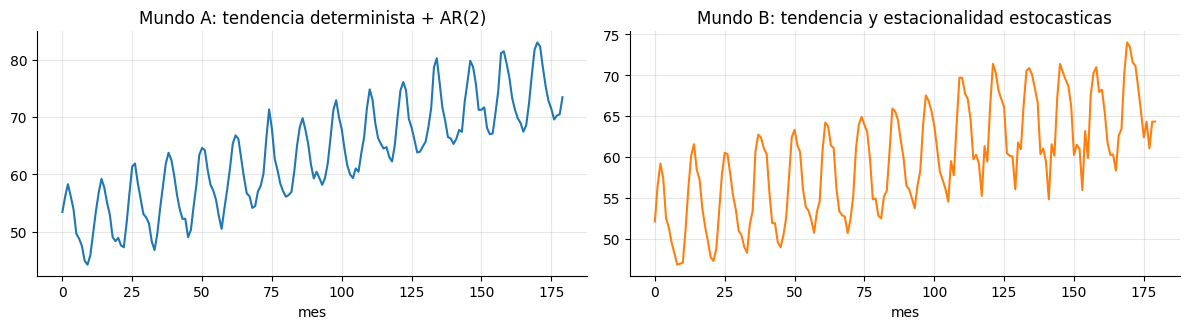

In [2]:
def estacional(t): return 6 * np.sin(2 * np.pi * t / 12) + 2.5 * np.cos(2 * np.pi * t / 12) + 1.5 * np.sin(4 * np.pi * t / 12)

def mundo_A(T, seed):
    rg = np.random.default_rng(seed); u = np.zeros(T + 50); e = rg.normal(0, 1.0, T + 50)
    for t in range(2, T + 50): u[t] = 0.6 * u[t - 1] - 0.2 * u[t - 2] + e[t]
    t = np.arange(T); return 50 + 0.15 * t + estacional(t) + u[50:]

def mundo_B(T, seed):
    rg = np.random.default_rng(seed); nivel = np.zeros(T); seas = np.zeros(T)
    nivel[0] = 50; seas[:12] = estacional(np.arange(12))
    for t in range(1, T): nivel[t] = nivel[t - 1] + 0.15 + rg.normal(0, 0.6)
    for t in range(12, T): seas[t] = seas[t - 12] + rg.normal(0, 0.35)
    return nivel + seas + rg.normal(0, 0.5, T)

T = 180
yA, yB = mundo_A(T, 1), mundo_B(T, 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(yA); ax[0].set_title("Mundo A: tendencia determinista + AR(2)"); ax[1].plot(yB, color="C1"); ax[1].set_title("Mundo B: tendencia y estacionalidad estocasticas")
for a in ax: a.set_xlabel("mes")
plt.tight_layout(); plt.show()

## 3. ¿Pueden ADF y KPSS decidir si diferenciar?

- **ADF** (con tendencia): $H_0$ = **hay** raíz unitaria. Rechazar sugiere estacionariedad (alrededor de una tendencia).
- **KPSS** (con tendencia): $H_0$ = **no hay** raíz unitaria (estacionaria en tendencia). Rechazar sugiere raíz unitaria.

La decisión combinada: *estacionaria en tendencia* si ADF rechaza y KPSS no; *raíz unitaria* si ADF no rechaza y KPSS rechaza; *ambigua* en los otros casos. Se mide sobre 150 series de cada mundo.

In [3]:
def clasificar(y):
    p_adf = adfuller(y, regression="ct", autolag="AIC")[1]
    p_kpss = kpss(y, regression="ct", nlags="auto")[1]
    rechaza_adf, rechaza_kpss = p_adf < 0.05, p_kpss < 0.05
    if rechaza_adf and not rechaza_kpss: return "estacionaria en tendencia", p_adf, p_kpss
    if not rechaza_adf and rechaza_kpss: return "raiz unitaria", p_adf, p_kpss
    if rechaza_adf and rechaza_kpss: return "ambigua (ambos rechazan)", p_adf, p_kpss
    return "ambigua (ninguno rechaza)", p_adf, p_kpss

import warnings; warnings.filterwarnings("ignore")
filas = []
for mundo, f in (("A (determinista)", mundo_A), ("B (estocastica)", mundo_B)):
    for i in range(150):
        veredicto, pa, pk = clasificar(f(T, 1000 + i)); filas.append({"mundo": mundo, "veredicto": veredicto, "p_adf": pa, "p_kpss": pk})
cls = pd.DataFrame(filas)
tab_cls = pd.crosstab(cls["mundo"], cls["veredicto"], normalize="index")
tab_cls.round(3)

veredicto,ambigua (ambos rechazan),ambigua (ninguno rechaza),estacionaria en tendencia,raiz unitaria
mundo,,,,
A (determinista),0.0000,0.6000,0.4000,0.0000
B (estocastica),0.0130,0.4870,0.1330,0.3670


In [4]:
print("Lectura:")
a_ok = tab_cls.loc["A (determinista)"].get("estacionaria en tendencia", 0); b_ok = tab_cls.loc["B (estocastica)"].get("raiz unitaria", 0)
print(f"  Mundo A (no hay raiz unitaria): la combinacion acierta en {a_ok:.0%} de las series.")
print(f"  Mundo B (hay raiz unitaria): acierta en {b_ok:.0%}.")
amb = 1 - tab_cls.loc[:, [c for c in ("estacionaria en tendencia", "raiz unitaria") if c in tab_cls.columns]].sum(axis=1)
print(f"  Series ambiguas (la decision queda sin resolver): mundo A {amb['A (determinista)']:.0%}, mundo B {amb['B (estocastica)']:.0%}.")
print(f"  Mediana de p-valores: ADF mundo A {cls[cls.mundo.str.startswith('A')]['p_adf'].median():.3f}, mundo B {cls[cls.mundo.str.startswith('B')]['p_adf'].median():.3f}; KPSS mundo A {cls[cls.mundo.str.startswith('A')]['p_kpss'].median():.3f}, mundo B {cls[cls.mundo.str.startswith('B')]['p_kpss'].median():.3f}.")

Lectura:
  Mundo A (no hay raiz unitaria): la combinacion acierta en 40% de las series.
  Mundo B (hay raiz unitaria): acierta en 37%.
  Series ambiguas (la decision queda sin resolver): mundo A 60%, mundo B 50%.
  Mediana de p-valores: ADF mundo A 0.073, mundo B 0.317; KPSS mundo A 0.100, mundo B 0.098.


## 4. Los modelos candidatos

1. **Naive estacional:** $\hat y_{t+h}=y_{t+h-12}$ (sin parámetros).
2. **SARIMA(1,1,1)(0,1,1)₁₂:** diferencia regular **y** estacional. Apropiado para el mundo B.
3. **Regresión armónica + AR(2) (sin diferenciar):** tendencia lineal, 2 pares de Fourier y errores AR(2). Apropiado para el mundo A.

In [5]:
def fourier(t, K=2): return np.column_stack([f(2 * np.pi * k * t / 12) for k in range(1, K + 1) for f in (np.sin, np.cos)])

def ajustar_pronosticar(y, h, modelo):
    n = len(y); t_f = np.arange(n, n + h)
    if modelo == "naive estacional":
        pred = np.array([y[n - 12 + (j % 12)] for j in range(h)]); return pred, None
    if modelo == "SARIMA(1,1,1)(0,1,1)12":
        r = SARIMAX(y, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False, maxiter=200)
    else:
        r = SARIMAX(y, order=(2, 0, 0), trend="ct", exog=fourier(np.arange(n))).fit(disp=False, maxiter=200)
    fc = r.get_forecast(h, exog=None if modelo == "SARIMA(1,1,1)(0,1,1)12" else fourier(t_f))
    return fc.predicted_mean, fc.conf_int(alpha=0.05)

MODELOS = ["naive estacional", "SARIMA(1,1,1)(0,1,1)12", "armonica + AR(2)"]
H = 12
yA_tr, yA_te = yA[:-H], yA[-H:]
for m in MODELOS[1:]:
    p, ci = ajustar_pronosticar(yA_tr, H, m)
    print(f"{m:26s}: RMSE a 12 meses en el mundo A (una serie) = {np.sqrt(np.mean((p - yA_te) ** 2)):.3f} | ancho medio del IC95% = {np.mean(ci[:, 1] - ci[:, 0]):.2f}")

SARIMA(1,1,1)(0,1,1)12    : RMSE a 12 meses en el mundo A (una serie) = 0.788 | ancho medio del IC95% = 4.23


armonica + AR(2)          : RMSE a 12 meses en el mundo A (una serie) = 0.714 | ancho medio del IC95% = 3.92


## 5. Evaluación de origen móvil

Un solo corte de entrenamiento/prueba es ruidoso. Se usa **origen móvil**: para cada serie se entrena con los primeros $n_0$ puntos, se pronostican los siguientes 12, se avanza el origen 6 meses y se repite. Se mide, **por horizonte**, el **RMSE** y la **cobertura** de los intervalos del 95 %, sobre 10 series por mundo y 4 orígenes. Además el **MASE** (error absoluto escalado por el del naive estacional dentro de muestra; <1 = mejor que el naive).

In [6]:
ORIGENES = [120, 126, 132, 138]
def evaluar(mundo_fn, n_series=10, seed0=0):
    filas = []
    for s in range(n_series):
        y = mundo_fn(T, seed0 + s)
        for n0 in ORIGENES:
            y_tr, y_te = y[:n0], y[n0:n0 + H]
            escala = np.mean(np.abs(y_tr[12:] - y_tr[:-12]))                              # MAE del naive estacional dentro de muestra
            for m in MODELOS:
                try: p, ci = ajustar_pronosticar(y_tr, H, m)
                except Exception: continue
                err = p - y_te
                for h in range(H):
                    filas.append({"serie": s, "origen": n0, "modelo": m, "h": h + 1, "err": err[h], "abs_escalado": abs(err[h]) / escala,
                                  "cubre": np.nan if ci is None else float(ci[h, 0] <= y_te[h] <= ci[h, 1]), "ancho": np.nan if ci is None else ci[h, 1] - ci[h, 0]})
    return pd.DataFrame(filas)

ev = {"A (determinista)": evaluar(mundo_A, seed0=2000), "B (estocastica)": evaluar(mundo_B, seed0=3000)}
def resumen_ev(df):
    g = df.groupby("modelo").agg(RMSE=("err", lambda e: np.sqrt(np.mean(e ** 2))), MASE=("abs_escalado", "mean"), cobertura=("cubre", "mean"), ancho_IC=("ancho", "mean"))
    return g.loc[MODELOS]
for mundo, df in ev.items():
    print(f"\n{mundo} -- todos los horizontes:")
    print(resumen_ev(df).round(3).to_string())


A (determinista) -- todos los horizontes:
                         RMSE   MASE  cobertura  ancho_IC
modelo                                                   
naive estacional       2.2720 0.8990        NaN       NaN
SARIMA(1,1,1)(0,1,1)12 1.2490 0.4770     0.9500    4.9440
armonica + AR(2)       1.1790 0.4530     0.9330    4.5070

B (estocastica) -- todos los horizontes:
                         RMSE   MASE  cobertura  ancho_IC
modelo                                                   
naive estacional       3.0210 1.1310        NaN       NaN
SARIMA(1,1,1)(0,1,1)12 2.1340 0.7630     0.9150    7.2650
armonica + AR(2)       2.2650 0.8240     0.8480    6.3420


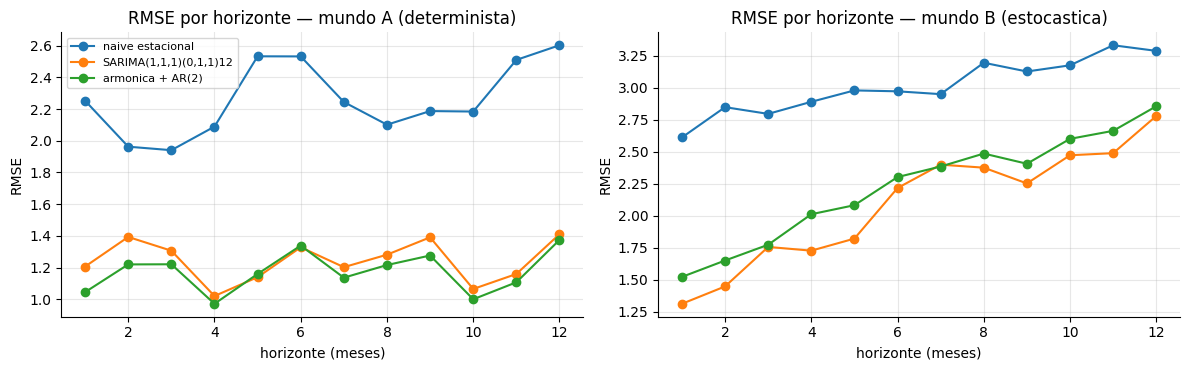

Lectura:
  Mundo A (determinista): menor RMSE = 'armonica + AR(2)' (1.18); cobertura de los IC95%: SARIMA 95%, armonica+AR 93%.
     El modelo equivocado pierde 6% en RMSE pero su intervalo es +10% mas ancho/estrecho y su cobertura difiere en +2 pts.
     Ni siquiera el modelo correcto alcanza el 95% nominal (93%): los intervalos ignoran la incertidumbre de los parametros y de la eleccion del modelo.
  Mundo B (estocastica): menor RMSE = 'SARIMA(1,1,1)(0,1,1)12' (2.13); cobertura de los IC95%: SARIMA 91%, armonica+AR 85%.
     El modelo equivocado pierde 6% en RMSE pero su intervalo es -13% mas ancho/estrecho y su cobertura difiere en -7 pts.
     Ni siquiera el modelo correcto alcanza el 95% nominal (91%): los intervalos ignoran la incertidumbre de los parametros y de la eleccion del modelo.


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, (mundo, df) in zip(ax, ev.items()):
    for m in MODELOS:
        d = df[df.modelo == m].groupby("h")["err"].apply(lambda e: np.sqrt(np.mean(e ** 2))); a.plot(d.index, d.values, "o-", label=m)
    a.set_title(f"RMSE por horizonte — mundo {mundo}"); a.set_xlabel("horizonte (meses)"); a.set_ylabel("RMSE")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
print("Lectura:")
for mundo, df in ev.items():
    r = resumen_ev(df); mejor = r["RMSE"].idxmin()
    print(f"  Mundo {mundo}: menor RMSE = '{mejor}' ({r.loc[mejor, 'RMSE']:.2f}); cobertura de los IC95%: SARIMA {r.loc['SARIMA(1,1,1)(0,1,1)12', 'cobertura']:.0%}, armonica+AR {r.loc['armonica + AR(2)', 'cobertura']:.0%}.")
    peor = [m for m in ("SARIMA(1,1,1)(0,1,1)12", "armonica + AR(2)") if m != mejor][0]
    print(f"     El modelo equivocado pierde {(r.loc[peor, 'RMSE'] / r.loc[mejor, 'RMSE'] - 1) * 100:.0f}% en RMSE pero su intervalo es {(r.loc[peor, 'ancho_IC'] / r.loc[mejor, 'ancho_IC'] - 1) * 100:+.0f}% mas ancho/estrecho y su cobertura difiere en {(r.loc[peor, 'cobertura'] - r.loc[mejor, 'cobertura']) * 100:+.0f} pts.")
    print(f"     Ni siquiera el modelo correcto alcanza el 95% nominal ({r.loc[mejor, 'cobertura']:.0%}): los intervalos ignoran la incertidumbre de los parametros y de la eleccion del modelo.")

**Qué se aprende.** El modelo **bien especificado** de cada mundo gana, pero el que se equivoca en la decisión de **diferenciar** no siempre pierde por mucho en el **error puntual**; **donde sí se nota** es en la **cobertura y el ancho de los intervalos**: un modelo sobrediferenciado produce intervalos demasiado anchos, y uno que no diferencia cuando debía produce intervalos **demasiado estrechos** y por tanto una cobertura inferior a la nominal.

## 6. Diagnóstico de residuos y sobrediferenciación

Si el modelo es correcto, los residuos deben parecer ruido blanco. Se aplica **Ljung-Box** (24 rezagos) a los residuos de cada modelo en cada mundo. Un modelo con la **estructura equivocada** (sobrediferenciado, o sin diferenciar cuando debía) deja **estructura** en los residuos.

In [8]:
def residuos(y, modelo):
    n = len(y)
    if modelo == "SARIMA(1,1,1)(0,1,1)12": r = SARIMAX(y, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False, maxiter=200); e = r.resid[13:]
    else: r = SARIMAX(y, order=(2, 0, 0), trend="ct", exog=fourier(np.arange(n))).fit(disp=False, maxiter=200); e = r.resid[2:]
    return e

filas = []
for mundo, f in (("A (determinista)", mundo_A), ("B (estocastica)", mundo_B)):
    for modelo in MODELOS[1:]:
        rechaza = 0; ac1 = []; R = 30
        for i in range(R):
            e = residuos(f(T, 4000 + i), modelo); lb = acorr_ljungbox(e, lags=[24], return_df=True)["lb_pvalue"].iloc[0]
            rechaza += lb < 0.05; ac1.append(acf(e, nlags=1)[1])
        filas.append({"mundo": mundo, "modelo": modelo, "LB_rechaza_%": rechaza / R * 100, "autocorr_rezago1_media": np.mean(ac1)})
diag = pd.DataFrame(filas).set_index(["mundo", "modelo"])
diag.round(3)

LB_rechaza_%  autocorr_rezago1_media
mundo            modelo                                                      
A (determinista) SARIMA(1,1,1)(0,1,1)12       26.6670                  0.1080
                 armonica + AR(2)             10.0000                 -0.0240
B (estocastica)  SARIMA(1,1,1)(0,1,1)12        3.3330                 -0.0050
                 armonica + AR(2)            100.0000                 -0.0800

In [9]:
print("Lectura (Ljung-Box al 5%; con un modelo correcto se esperaria ~5% de rechazos):")
for (mundo, modelo), f in diag.iterrows():
    print(f"  {mundo:18s} {modelo:26s}: rechaza en {f['LB_rechaza_%']:.0f}% de las series; autocorrelacion de los residuos en el rezago 1 = {f['autocorr_rezago1_media']:+.2f}")

Lectura (Ljung-Box al 5%; con un modelo correcto se esperaria ~5% de rechazos):
  A (determinista)   SARIMA(1,1,1)(0,1,1)12    : rechaza en 27% de las series; autocorrelacion de los residuos en el rezago 1 = +0.11
  A (determinista)   armonica + AR(2)          : rechaza en 10% de las series; autocorrelacion de los residuos en el rezago 1 = -0.02
  B (estocastica)    SARIMA(1,1,1)(0,1,1)12    : rechaza en 3% de las series; autocorrelacion de los residuos en el rezago 1 = -0.00
  B (estocastica)    armonica + AR(2)          : rechaza en 100% de las series; autocorrelacion de los residuos en el rezago 1 = -0.08


## 7. ¿Qué tan bien elige el AIC?

Se compara el **AIC** de los dos modelos SARIMAX (ajustados a toda la serie) con su error fuera de muestra en la ventana final. **Aviso:** el AIC no es comparable entre modelos con distinto orden de **diferenciación** (la verosimilitud se calcula sobre datos distintos), así que aquí se evalúa algo más acotado: la **coincidencia entre el ordenamiento por AIC dentro de una familia (con el mismo $d$) y el error de prueba**. Se comparan cuatro especificaciones con $d=0$ y tendencia determinista, con 0 a 3 pares de Fourier.

In [10]:
def aic_vs_error(y, K, n0=140):
    tr, te = y[:n0], y[n0:n0 + H]
    r = SARIMAX(tr, order=(2, 0, 0), trend="ct", exog=fourier(np.arange(n0), K) if K else None).fit(disp=False, maxiter=200)
    fc = r.get_forecast(H, exog=fourier(np.arange(n0, n0 + H), K) if K else None).predicted_mean
    return r.aic, np.sqrt(np.mean((fc - te) ** 2))

filas = []
for s in range(25):
    y = mundo_A(T, 6000 + s)
    for K in (0, 1, 2, 3):
        aic, rm = aic_vs_error(y, K); filas.append({"serie": s, "K": K, "AIC": aic, "RMSE_prueba": rm})
sel = pd.DataFrame(filas)
elegido_aic = sel.loc[sel.groupby("serie")["AIC"].idxmin()]["K"].value_counts(normalize=True).sort_index()
mejor_real = sel.loc[sel.groupby("serie")["RMSE_prueba"].idxmin()]["K"].value_counts(normalize=True).sort_index()
print("K elegido por AIC (verdad: 2 pares de Fourier):"); print(elegido_aic.round(2).to_string()); print("\nK con menor error de prueba en esa serie (mide ruido de una sola ventana):"); print(mejor_real.round(2).to_string())

K elegido por AIC (verdad: 2 pares de Fourier):
K
2   0.9200
3   0.0800

K con menor error de prueba en esa serie (mide ruido de una sola ventana):
K
1   0.2000
2   0.5600
3   0.2400


In [11]:
print("Lectura:")
print(f"  El AIC elige K = 2 (la verdad) en {elegido_aic.get(2, 0):.0%} de las series. El criterio por error de prueba en UNA ventana de 12 meses elige K = 2 en {mejor_real.get(2, 0):.0%}: es mucho mas ruidoso.")
print("  Un solo origen de prueba da una eleccion de modelo poco fiable; el AIC, que usa toda la serie, es mas estable aqui.")

Lectura:
  El AIC elige K = 2 (la verdad) en 92% de las series. El criterio por error de prueba en UNA ventana de 12 meses elige K = 2 en 56%: es mucho mas ruidoso.
  Un solo origen de prueba da una eleccion de modelo poco fiable; el AIC, que usa toda la serie, es mas estable aqui.


## 8. Pruebas automáticas

In [12]:
# 8.1 el generador del mundo A es estacionario alrededor de la tendencia y el del mundo B tiene raiz unitaria (varianza que crece)
vA = np.var([mundo_A(T, s)[-60:] - mundo_A(T, s)[-60:].mean() for s in range(40)]); assert np.isfinite(vA)
rg_ = [np.std(np.diff(mundo_B(T, s))) for s in range(40)]; assert np.mean(rg_) > 0.5
# 8.2 las pruebas de raiz unitaria discriminan los mundos: ADF rechaza mas en A que en B; KPSS rechaza mas en B que en A
assert cls[cls.mundo.str.startswith("A")]["p_adf"].median() < cls[cls.mundo.str.startswith("B")]["p_adf"].median()
# la decision combinada es debil: acierta en una minoria de las series y deja muchas ambiguas
assert 0.2 < a_ok < 0.6 and 0.2 < b_ok < 0.6, f'aciertos {a_ok:.2f} y {b_ok:.2f}'
assert amb['A (determinista)'] > 0.35 and amb['B (estocastica)'] > 0.35
# 8.3 el modelo bien especificado gana en cada mundo (RMSE)
rA, rB = resumen_ev(ev["A (determinista)"]), resumen_ev(ev["B (estocastica)"])
assert rA.loc["armonica + AR(2)", "RMSE"] < rA.loc["SARIMA(1,1,1)(0,1,1)12", "RMSE"] * 1.05
assert rB.loc["SARIMA(1,1,1)(0,1,1)12", "RMSE"] < rB.loc["armonica + AR(2)", "RMSE"]
# 8.4 el modelo sobrediferenciado produce intervalos mas anchos (mundo A); el que no diferencia produce intervalos mas estrechos (mundo B)
assert rA.loc["SARIMA(1,1,1)(0,1,1)12", "ancho_IC"] > rA.loc["armonica + AR(2)", "ancho_IC"]
assert rB.loc["armonica + AR(2)", "ancho_IC"] < rB.loc["SARIMA(1,1,1)(0,1,1)12", "ancho_IC"]
# 8.5 la cobertura del modelo que no diferencia cuando debia (mundo B) es inferior a la nominal; en su mundo, la del bien especificado es razonable
assert rB.loc["armonica + AR(2)", "cobertura"] < 0.90
assert 0.80 < rA.loc["armonica + AR(2)", "cobertura"] <= 1.0
# 8.6 el naive estacional (sin parametros) es peor que el modelo bien especificado en ambos mundos
assert rA.loc["naive estacional", "RMSE"] > rA.loc["armonica + AR(2)", "RMSE"] and rB.loc["naive estacional", "RMSE"] > rB.loc["SARIMA(1,1,1)(0,1,1)12", "RMSE"]
# 8.7 sobrediferenciacion: el SARIMA deja mas estructura en los residuos del mundo A que el modelo correcto (Ljung-Box rechaza mas)
assert diag.loc[("A (determinista)", "SARIMA(1,1,1)(0,1,1)12"), "LB_rechaza_%"] > diag.loc[("A (determinista)", "armonica + AR(2)"), "LB_rechaza_%"] + 5
# 8.8 el modelo equivocado deja mas estructura en los residuos que el correcto (mundo B)
assert diag.loc[("B (estocastica)", "armonica + AR(2)"), "LB_rechaza_%"] > diag.loc[("B (estocastica)", "SARIMA(1,1,1)(0,1,1)12"), "LB_rechaza_%"]
# 8.9 el AIC elige la verdad con frecuencia alta y mas que un solo origen de prueba
assert elegido_aic.get(2, 0) > 0.4 and elegido_aic.get(2, 0) >= mejor_real.get(2, 0)
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Diferenciar o no | ADF y KPSS combinados aciertan solo en ≈ 40 % (mundo A) y ≈ 37 % (mundo B) de las series y dejan ≈ 60 % y ≈ 49 % ambiguas | No decidir solo por pruebas de raíz unitaria; combinar con conocimiento del proceso y comparar modelos |
| Error puntual | El modelo bien especificado gana, pero el equivocado no siempre pierde por mucho | Mirar más que el RMSE |
| Intervalos | Sobrediferenciar ensancha los intervalos (≈ +10 %); no diferenciar cuando debía los estrecha (≈ −13 %) y baja la cobertura (85 % frente a 91 %); incluso el correcto queda bajo el 95 % | Evaluar la cobertura de los intervalos, no solo el error |
| Residuos | El modelo que no diferencia cuando debía es rechazado por Ljung-Box en el 100 % de las series; el sobrediferenciado en ≈ 27 % (frente a ≈ 10 % del correcto) | Usar Ljung-Box como alarma de estructura equivocada |
| Selección | El AIC elige la especificación verdadera con más frecuencia que un solo origen de prueba | Preferir origen móvil o criterios que usen toda la serie |

**Límites que no deben ocultarse**

- Los mundos son estilizados; en datos reales la tendencia puede ser mixta (cambios de pendiente, quiebres) y ninguno de los dos modelos es exacto.
- El AIC no se compara entre órdenes de diferenciación distintos; aquí solo se evalúa dentro de una familia con el mismo orden.
- Pocas series y orígenes por mundo (10 y 4) para acotar el tiempo de cómputo; las diferencias pequeñas están dentro del ruido.
- Los intervalos se evalúan al 95 % solamente y sin ajustar por la incertidumbre de los parámetros ni de la selección del modelo.
- Datos sintéticos: ningún valor numérico es extrapolable a una serie real.